# Cierre — Corrección en carreteras de alto tránsito y valor del modelo sin aforos
**Equipo 20 · Proyecto ML–SEDP (Green Stops, corredor CDMX–Acapulco)**

Este notebook atiende los comentarios del asesor al Avance 5:

1. *"El modelo todavía se queda corto en las carreteras con más tráfico […] vale la pena intentar corregirlo."* → Secciones 1 y 2.
2. *"Dejen claro que su valor está en los corredores sin aforos."* → Sección 3.
3. *"Agreguen la sección de contribución individual."* → Sección 5.

Se usa **exactamente** el esquema del Avance 5: misma tabla (`FE_TOP_Model_Table_v2.csv`), mismo modelo final (Voting de Ridge, Elastic Net, SVR y Gradient Boosting), misma validación espacial (15 regiones contiguas, 5 pliegues, purga de 40 km) y mismas métricas. Así, cualquier cambio en los resultados se debe sólo a la corrección que se prueba.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics.pairwise import haversine_distances
from threadpoolctl import threadpool_limits

import tdpa_comun as tc
from tdpa_comun import TARGET, PreparadorSeguro, preparar_datos
from validacion_regiones import construir_folds_regiones

%matplotlib inline
warnings.filterwarnings("ignore")
SEED, THREADS = 20, 2
threadpool_limits(limits=THREADS)
np.random.seed(SEED)

ROOT = tc.encontrar_raiz()
TABLA = ROOT / "03_PROCESSED" / "FE_TOP_Model_Table_v2.csv"
TABLA_CTN = ROOT / "03_PROCESSED" / "FE_CTN_Prediction_Table_v2.csv"
OUT = ROOT / "06_RESULTS" / "CIERRE"
OUT.mkdir(parents=True, exist_ok=True)

tabla, train, test = preparar_datos(TABLA)
folds = construir_folds_regiones(train)
y = train[TARGET]
quintil_real = pd.qcut(train["tdpa"], 5, labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
CORTES = train["tdpa"].quantile([1/3, 2/3]).to_numpy()

Tabla maestra (1075, 279) | train 703 | test externo 23 | purgados 349


## 0. Modelo del Avance 5 y funciones de evaluación
El `VotingPonderado` es el mismo Voting del Avance 5 (promedio simple de los cuatro modelos). Con `fuerza = 0` es idéntico; con `fuerza > 0` da más peso al entrenar a los sitios con tránsito por encima de la mediana (se usa en la corrección A).

In [2]:
# Hiperparámetros elegidos en el Avance 5
ALPHA = 20
GB_MEJOR = {"learning_rate": 0.03, "max_iter": 150, "min_samples_leaf": 20, "l2_regularization": 0.0}

def pipe(estimador):
    return Pipeline([("prep", PreparadorSeguro(modo="Filtro + PCA")), ("modelo", estimador)])

def modelos_base():
    return [pipe(Ridge(alpha=ALPHA)),
            pipe(ElasticNet(alpha=0.01, l1_ratio=0.9, max_iter=20000, random_state=SEED)),
            pipe(SVR(kernel="rbf", C=10, epsilon=0.15, gamma="scale")),
            pipe(HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **GB_MEJOR))]

class VotingPonderado(BaseEstimator, RegressorMixin):
    # Promedio de los 4 modelos. fuerza > 0: peso = 1 + fuerza * (desviaciones estándar por encima de la mediana)
    def __init__(self, fuerza=0.0):
        self.fuerza = fuerza
    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        w = 1 + self.fuerza * np.clip((y - np.median(y)) / y.std(), 0, None)
        w = w / w.mean()
        self.modelos_ = [m.fit(X, y, modelo__sample_weight=w) for m in modelos_base()]
        return self
    def predict(self, X):
        return np.mean([m.predict(X) for m in self.modelos_], axis=0)

def predecir_cv(datos, fuerza=0.0):
    # Predicciones fuera de pliegue con la validación espacial del Avance 5
    oof = pd.Series(np.nan, index=datos.index)
    for _, itr, iva in folds:
        tr = datos.loc[itr]
        oof[iva] = VotingPonderado(fuerza).fit(tr, tr[TARGET]).predict(datos.loc[iva])
    return oof

def resumen(p):
    r = y - p
    alto, bajo = quintil_real == "Q5 (alto)", quintil_real == "Q1 (bajo)"
    pred = np.exp(p)
    return {"rmse_log": np.mean([np.sqrt(((y[iva] - p[iva]) ** 2).mean()) for _, _, iva in folds]),
            "spearman": spearmanr(y, p)[0],
            "acierto_categoria": float(np.mean(np.digitize(train["tdpa"], CORTES) == np.digitize(pred, CORTES))),
            "sesgo_Q5_alto": r[alto].mean(), "rmse_Q5_alto": np.sqrt((r[alto] ** 2).mean()),
            "sesgo_Q1_bajo": r[bajo].mean(), "rmse_Q1_bajo": np.sqrt((r[bajo] ** 2).mean()),
            "wape_pct": 100 * np.abs(train["tdpa"] - pred).sum() / train["tdpa"].sum()}

OOF = {"Avance 5 (sin cambios)": predecir_cv(train)}
p0 = OOF["Avance 5 (sin cambios)"]
print({k: round(v, 4) for k, v in resumen(p0).items()})

{'rmse_log': np.float64(0.6744), 'spearman': np.float64(0.8129), 'acierto_categoria': 0.7055, 'sesgo_Q5_alto': np.float64(0.5033), 'rmse_Q5_alto': np.float64(0.7897), 'sesgo_Q1_bajo': np.float64(-0.6625), 'rmse_Q1_bajo': np.float64(0.927), 'wape_pct': np.float64(48.3055)}


## 1. Diagnóstico: ¿dónde y por qué se queda corto el modelo?
El sesgo es `real − predicho` en escala log: **positivo = el modelo subestima**. Un sesgo de +0.5 equivale a predecir cerca del 60% del tránsito real.

### 1.1 El sesgo depende de cómo se agrupe
El Gráfico 3 del Avance 5 agrupa los sitios por su tránsito **real**. Aquí se compara con agrupar por el tránsito **predicho**, que es lo único que se conoce en un sitio sin aforo.

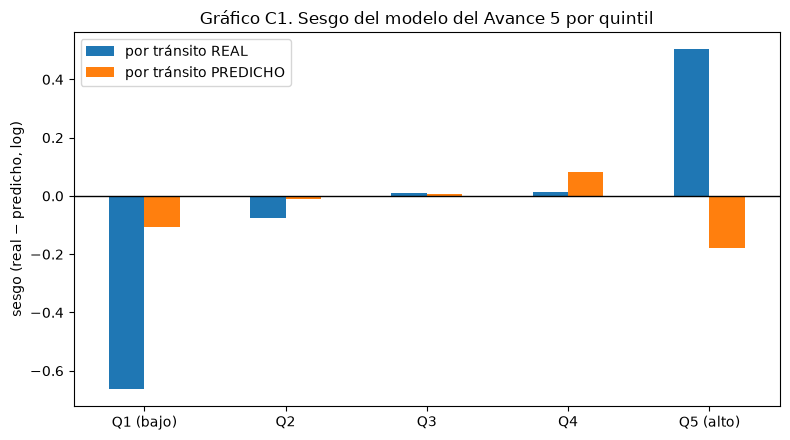

,por tránsito REAL,por tránsito PREDICHO
Q1 (bajo),-0.662,-0.107
Q2,-0.077,-0.009
Q3,0.011,0.005
Q4,0.014,0.081
Q5 (alto),0.503,-0.180


**Lectura.** Agrupando por tránsito real, el quintil más alto se subestima (+0.50) y el más bajo se sobreestima (-0.66). Agrupando por tránsito predicho, el sesgo del quintil más alto es -0.18. La pendiente de la predicción respecto al real es 0.63 (aplanamiento), pero la del real respecto a la predicción es 0.99 (≈1 = calibrado). Es decir: el modelo no puede separar del todo a las carreteras más cargadas con las variables que tiene y las acerca al promedio, pero **cuando el modelo predice un valor, en promedio ese valor se cumple**. Por eso una recalibración lineal de las predicciones no corrige nada: la corrección tiene que venir de mejor información.

In [3]:
resid = y - p0
quintil_pred = pd.qcut(p0, 5, labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
sesgos = pd.DataFrame({"por tránsito REAL": resid.groupby(quintil_real).mean(),
                       "por tránsito PREDICHO": resid.groupby(quintil_pred).mean()})
ax = sesgos.plot.bar(figsize=(8, 4.5), rot=0)
ax.axhline(0, color="k", lw=1)
ax.set(title="Gráfico C1. Sesgo del modelo del Avance 5 por quintil", ylabel="sesgo (real − predicho, log)", xlabel="")
plt.tight_layout(); plt.savefig(OUT / "c1_sesgo_real_vs_predicho.png", dpi=120); plt.show()
pend_p_y = np.polyfit(y, p0, 1)[0]      # cuánto sube la predicción cuando el real sube 1
pend_y_p = np.polyfit(p0, y, 1)[0]      # cuánto sube el real cuando la predicción sube 1
display(sesgos.round(3))
display(Markdown(
    f"**Lectura.** Agrupando por tránsito real, el quintil más alto se subestima ({sesgos.iloc[4, 0]:+.2f}) y el más bajo se "
    f"sobreestima ({sesgos.iloc[0, 0]:+.2f}). Agrupando por tránsito predicho, el sesgo del quintil más alto es "
    f"{sesgos.iloc[4, 1]:+.2f}. La pendiente de la predicción respecto al real es {pend_p_y:.2f} (aplanamiento), pero la del "
    f"real respecto a la predicción es {pend_y_p:.2f} (≈1 = calibrado). Es decir: el modelo no puede separar del todo a las "
    f"carreteras más cargadas con las variables que tiene y las acerca al promedio, pero **cuando el modelo predice un valor, "
    f"en promedio ese valor se cumple**. Por eso una recalibración lineal de las predicciones no corrige nada: la corrección "
    f"tiene que venir de mejor información."))

### 1.2 ¿Qué carreteras concentran la subestimación?

In [4]:
d = train.assign(pred=np.exp(p0), resid=resid, flujo_cero=train["red_flujo_paso"] == 0,
                 cuota_sict=train["toll_road"].astype(bool), cuota_rnc=train["fe_peaje"] == 1)
por_carretera = (d.groupby("carretera").agg(sitios=("resid", "size"), tdpa_real_mediana=("tdpa", "median"),
                                            tdpa_predicho_mediana=("pred", "median"), sesgo=("resid", "mean"),
                                            pct_flujo_paso_cero=("flujo_cero", "mean"), cuota_SICT=("cuota_sict", "mean"),
                                            cuota_RNC=("cuota_rnc", "mean"))
                 .query("sitios >= 5").sort_values("sesgo", ascending=False))
display(por_carretera.head(8).style.format({"tdpa_real_mediana": "{:,.0f}", "tdpa_predicho_mediana": "{:,.0f}", "sesgo": "{:+.2f}",
                                            "pct_flujo_paso_cero": "{:.0%}", "cuota_SICT": "{:.0%}", "cuota_RNC": "{:.0%}"}))
inconsistentes = int((train["toll_road"].astype(int) != train["fe_peaje"]).sum())
cuota_mal = int((train["toll_road"].astype(bool) & (train["fe_peaje"] == 0)).sum())
alto = quintil_real == "Q5 (alto)"
print(f"Sitios de entrenamiento donde la cuota de SICT y la de la RNC no coinciden: {inconsistentes} "
      f"({cuota_mal} son de cuota según SICT pero libres según el tramo asignado)")
print(f"Sitios con flujo de paso = 0: {d.flujo_cero.mean():.0%} del total y {d.flujo_cero[alto].mean():.0%} del quintil más alto")

,sitios,tdpa_real_mediana,tdpa_predicho_mediana,sesgo,pct_flujo_paso_cero,cuota_SICT,cuota_RNC
carretera,,,,,,,
México - Querétaro (Cuota),20,"74,583","21,200",+1.39,65%,100%,40%
México - Puebla (Cuota),9,"71,955","37,781",+0.83,56%,100%,78%
Toluca - Palmillas,15,"34,367","16,979",+0.66,80%,0%,33%
Santo Domingo - T. C. (México - Querétaro),5,"10,473","6,721",+0.49,20%,0%,0%
Toluca - Axixintla,5,"12,299","13,727",+0.48,80%,0%,0%
Acapulco - Zihuatanejo,15,"6,988","5,173",+0.44,100%,0%,0%
San Hipólito - Xalapa,12,"12,552","9,908",+0.42,100%,0%,0%
Apizaco - Tejocotal,7,"15,392","9,968",+0.40,100%,0%,0%


Sitios de entrenamiento donde la cuota de SICT y la de la RNC no coinciden: 52 (41 son de cuota según SICT pero libres según el tramo asignado)
Sitios con flujo de paso = 0: 85% del total y 68% del quintil más alto


**Hallazgo.** La subestimación se concentra en las autopistas troncales (México–Querétaro, México–Puebla, Toluca–Palmillas), y ahí aparecen **dos defectos de datos**, no del algoritmo:

1. **Cuota mal asignada.** Varios aforos de autopistas de cuota quedaron pegados a un tramo lateral de la RNC (calle, camino o enlace) y entran al modelo como vías libres.
2. **Flujo de paso en cero.** La variable `red_flujo_paso` se diseñó justo para medir el tránsito entre ciudades, pero vale 0 en buena parte de los aforos de esas mismas autopistas. La asignación recorre un solo cuerpo de la autopista; los aforos pegados al cuerpo contrario o a un enlace se quedan sin flujo.

## 2. Correcciones probadas
Todas se evalúan con la misma validación espacial.

- **A. Ponderar los sitios de alto tránsito** al entrenar (`fuerza` 0.5 y 1).
- **B. Corregir la cuota:** si SICT indica que la carretera es de cuota, `fe_peaje = 1`. La cuota es un atributo de la carretera (no del conteo), así que también se conoce en un corredor sin aforos.
- **C. Reparar el flujo de paso:** cada sitio toma el mayor `red_flujo_paso` entre los puntos de su misma carretera a 25 km o menos. Sólo usa variables de entrada, nunca el TDPA. Los 25 km son la distancia a la que desaparece la autocorrelación en el EDA; no se ajustó.
- **B + C** juntas, y **B + C + A**.

In [5]:
RADIO_KM = 25.0

def reparar_flujo(puntos, grupos, radio_km=RADIO_KM):
    # Máximo de red_flujo_paso entre los puntos del mismo grupo (carretera) dentro del radio
    out = puntos["red_flujo_paso"].copy()
    for _, g in puntos.groupby(grupos):
        if len(g) > 1:
            dist = haversine_distances(np.radians(g[["lat", "lon"]].to_numpy(float))) * 6371.0088
            v = g["red_flujo_paso"].to_numpy(float)
            out.loc[g.index] = [v[dist[i] <= radio_km].max() for i in range(len(g))]
    return out

flujo_reparado = reparar_flujo(tabla, tabla["carretera"])
def corregir(datos, cuota=True, flujo=True):
    d = datos.copy()
    if cuota:
        d["fe_peaje"] = np.maximum(d["fe_peaje"], d["toll_road"].astype(int))
    if flujo:
        d["red_flujo_paso"] = flujo_reparado.loc[d.index]
    return d

# nombre -> (corregir cuota, reparar flujo, fuerza de la ponderación)
CONFIG = {"A. Ponderar alto tránsito (0.5)": (False, False, 0.5), "A. Ponderar alto tránsito (1.0)": (False, False, 1.0),
          "B. Cuota corregida": (True, False, 0.0), "C. Flujo de paso reparado": (False, True, 0.0),
          "B + C": (True, True, 0.0), "B + C + A (0.5)": (True, True, 0.5)}
for nombre, (c_cuota, c_flujo, fuerza) in CONFIG.items():
    OOF[nombre] = predecir_cv(corregir(train, cuota=c_cuota, flujo=c_flujo), fuerza=fuerza)

comp = pd.DataFrame({k: resumen(v) for k, v in OOF.items()}).T
comp.to_csv(OUT / "correcciones_alto_transito.csv", encoding="utf-8-sig")
display(comp.style.format({"rmse_log": "{:.4f}", "spearman": "{:.3f}", "acierto_categoria": "{:.1%}", "sesgo_Q5_alto": "{:+.3f}",
                           "rmse_Q5_alto": "{:.3f}", "sesgo_Q1_bajo": "{:+.3f}", "rmse_Q1_bajo": "{:.3f}", "wape_pct": "{:.1f}"}))
print(f"Sitios con flujo de paso > 0: {(train.red_flujo_paso > 0).mean():.0%} -> {(flujo_reparado.loc[train.index] > 0).mean():.0%} tras la reparación")

,rmse_log,spearman,acierto_categoria,sesgo_Q5_alto,rmse_Q5_alto,sesgo_Q1_bajo,rmse_Q1_bajo,wape_pct
Avance 5 (sin cambios),0.6744,0.813,70.6%,+0.503,0.790,-0.662,0.927,48.3
A. Ponderar alto tránsito (0.5),0.6843,0.810,69.4%,+0.411,0.741,-0.697,0.952,49.9
A. Ponderar alto tránsito (1.0),0.6964,0.806,68.8%,+0.362,0.721,-0.730,0.979,51.6
B. Cuota corregida,0.6678,0.817,70.1%,+0.487,0.757,-0.657,0.924,47.9
C. Flujo de paso reparado,0.6597,0.820,69.4%,+0.519,0.754,-0.648,0.908,48.3
B + C,0.6587,0.820,69.8%,+0.513,0.744,-0.644,0.908,48.2
B + C + A (0.5),0.6609,0.820,69.7%,+0.418,0.679,-0.673,0.927,48.7


Sitios con flujo de paso > 0: 15% -> 30% tras la reparación


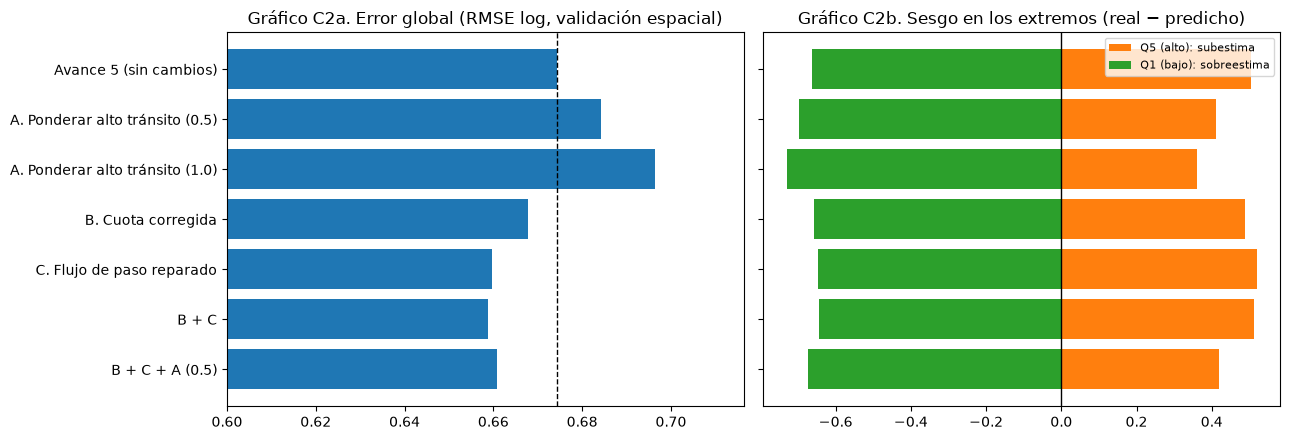

**Corrección adoptada: B + C + A (0.5).** Empatadas en RMSE global (±0.005): C. Flujo de paso reparado, B + C, B + C + A (0.5).

- Error global: RMSE log 0.6744 → 0.6609 (2.0% menos); Spearman 0.813 → 0.820.
- Quintil de mayor tránsito: RMSE 0.790 → 0.679 (14% menos); sesgo +0.503 → +0.418.
- Quintil de menor tránsito: sesgo -0.662 → -0.673.

**Lo que no se logró.** El sesgo del quintil alto sigue en +0.42: el modelo todavía predice cerca del 66% del tránsito real en las carreteras más cargadas. Ponderar por sí solo (variantes A) baja ese sesgo pero sube el error global y el sesgo del quintil bajo: mueve el error de un extremo al otro sin agregar información. Reparar los datos (B y C) es lo que baja el error en todos los rangos.

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
orden = comp.index[::-1]
axs[0].barh(orden, comp.loc[orden, "rmse_log"], color="tab:blue"); axs[0].axvline(comp.rmse_log.iloc[0], color="k", ls="--", lw=1)
axs[0].set(title="Gráfico C2a. Error global (RMSE log, validación espacial)", xlim=(0.6, comp.rmse_log.max() + 0.02))
axs[1].barh(orden, comp.loc[orden, "sesgo_Q5_alto"], color="tab:orange", label="Q5 (alto): subestima")
axs[1].barh(orden, comp.loc[orden, "sesgo_Q1_bajo"], color="tab:green", label="Q1 (bajo): sobreestima")
axs[1].axvline(0, color="k", lw=1); axs[1].set(title="Gráfico C2b. Sesgo en los extremos (real − predicho)"); axs[1].set_yticklabels([]); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "c2_correcciones.png", dpi=120); plt.show()

# Regla de decisión (la misma idea del Avance 5): las variantes a menos de 0.005 del mejor RMSE global se consideran
# empatadas; entre ellas se elige la de menor error en el quintil de mayor tránsito, que es el objetivo de esta etapa.
base = comp.iloc[0]
empatadas = comp[comp.rmse_log <= comp.rmse_log.min() + 0.005]
ELEGIDA = empatadas.rmse_Q5_alto.idxmin()
e = comp.loc[ELEGIDA]
display(Markdown(
    f"**Corrección adoptada: {ELEGIDA}.** Empatadas en RMSE global (±0.005): {', '.join(empatadas.index)}.\n\n"
    f"- Error global: RMSE log {base.rmse_log:.4f} → {e.rmse_log:.4f} ({100 * (1 - e.rmse_log / base.rmse_log):.1f}% menos); Spearman {base.spearman:.3f} → {e.spearman:.3f}.\n"
    f"- Quintil de mayor tránsito: RMSE {base.rmse_Q5_alto:.3f} → {e.rmse_Q5_alto:.3f} ({100 * (1 - e.rmse_Q5_alto / base.rmse_Q5_alto):.0f}% menos); "
    f"sesgo {base.sesgo_Q5_alto:+.3f} → {e.sesgo_Q5_alto:+.3f}.\n"
    f"- Quintil de menor tránsito: sesgo {base.sesgo_Q1_bajo:+.3f} → {e.sesgo_Q1_bajo:+.3f}.\n\n"
    f"**Lo que no se logró.** El sesgo del quintil alto sigue en {e.sesgo_Q5_alto:+.2f}: el modelo todavía predice cerca del "
    f"{100 * np.exp(-e.sesgo_Q5_alto):.0f}% del tránsito real en las carreteras más cargadas. Ponderar por sí solo (variantes A) baja ese sesgo "
    f"pero sube el error global y el sesgo del quintil bajo: mueve el error de un extremo al otro sin agregar información. "
    f"Reparar los datos (B y C) es lo que baja el error en todos los rangos."))

### 2.1 Efecto en el corredor MEX-095D
El corredor se usó una sola vez en el Avance 5 para la prueba externa. Aquí se vuelve a consultar **sólo para informar** el efecto de la corrección; la decisión de adoptarla se tomó arriba, con la validación espacial.

,rmse_log,sesgo,spearman,acierto_categoria
Avance 5,0.653,+0.279,0.627,70%
Corregido (B + C + A (0.5)),0.604,+0.089,0.607,70%


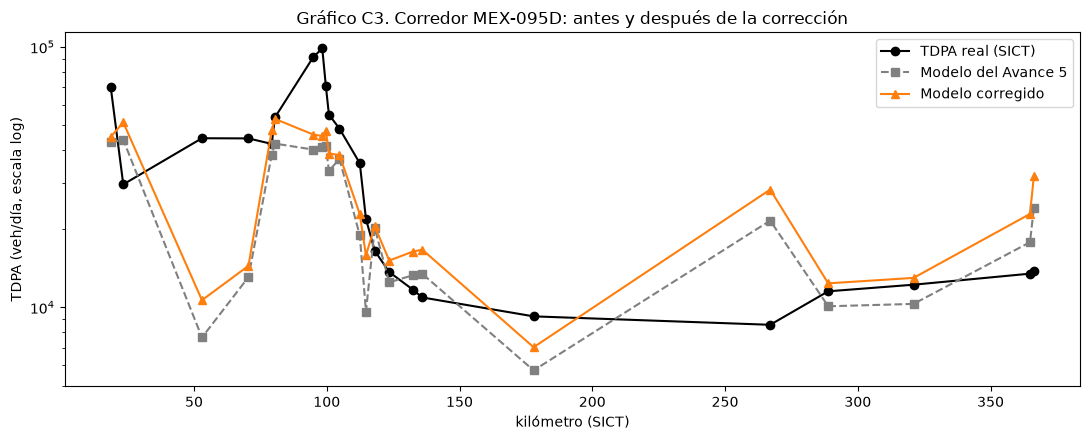

In [7]:
T = test.sort_values("KM")
yT, km = T[TARGET].to_numpy(float), T["KM"].to_numpy(float)
usa_cuota, usa_flujo, fuerza_final = CONFIG.get(ELEGIDA, (False, False, 0.0))
prep = lambda d: corregir(d, cuota=usa_cuota, flujo=usa_flujo)
modelo_a5 = VotingPonderado().fit(train, y)
modelo_corr = VotingPonderado(fuerza_final).fit(prep(train), y)
pT0, pT1 = modelo_a5.predict(T), modelo_corr.predict(prep(T))

def m_ext(p):
    r = yT - p
    return {"rmse_log": np.sqrt((r ** 2).mean()), "sesgo": r.mean(), "spearman": spearmanr(yT, p)[0],
            "acierto_categoria": float(np.mean(np.digitize(T["tdpa"], CORTES) == np.digitize(np.exp(p), CORTES)))}
ext = pd.DataFrame({"Avance 5": m_ext(pT0), f"Corregido ({ELEGIDA})": m_ext(pT1)}).T
ext.to_csv(OUT / "prueba_externa_corregida.csv", encoding="utf-8-sig")
display(ext.style.format({"rmse_log": "{:.3f}", "sesgo": "{:+.3f}", "spearman": "{:.3f}", "acierto_categoria": "{:.0%}"}))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(km, T["tdpa"], "o-", color="black", label="TDPA real (SICT)")
ax.plot(km, np.exp(pT0), "s--", color="gray", label="Modelo del Avance 5")
ax.plot(km, np.exp(pT1), "^-", color="tab:orange", label="Modelo corregido")
ax.set_yscale("log"); ax.set(xlabel="kilómetro (SICT)", ylabel="TDPA (veh/día, escala log)", title="Gráfico C3. Corredor MEX-095D: antes y después de la corrección")
ax.legend(); plt.tight_layout(); plt.savefig(OUT / "c3_corredor_corregido.png", dpi=120); plt.show()

## 3. ¿Cuánto vale el modelo cuando hay pocos aforos o ninguno?
El Avance 5 mostró que, con los 23 aforos de la MEX-095D, interpolar entre aforos vecinos es más preciso que el modelo. La pregunta que importa para transferir el método es otra: **¿qué pasa en un corredor con pocos aforos, o sin ninguno?**

Experimento: se simula que el corredor sólo tiene *k* aforos (elegidos al azar, 300 repeticiones) y se estiman los demás de tres formas:
- **Interpolación** entre los *k* aforos disponibles.
- **Modelo territorial** (no usa ningún aforo del corredor).
- **Combinación** usada en la caracterización: peso `exp(−d/80 km)` a la interpolación según la distancia al aforo disponible más cercano.

Con *k* = 0 no se puede interpolar; la única alternativa al modelo es el baseline por tipo de vía y cuota.

,km_por_aforo,interpolación,modelo,combinación
aforos_disponibles,,,,
2,174,0.832,0.603,0.620
3,116,0.714,0.606,0.582
4,87,0.578,0.602,0.519
6,58,0.439,0.604,0.434
8,43,0.360,0.607,0.380
12,29,0.289,0.606,0.323
16,22,0.265,0.578,0.294
20,17,0.232,0.556,0.259


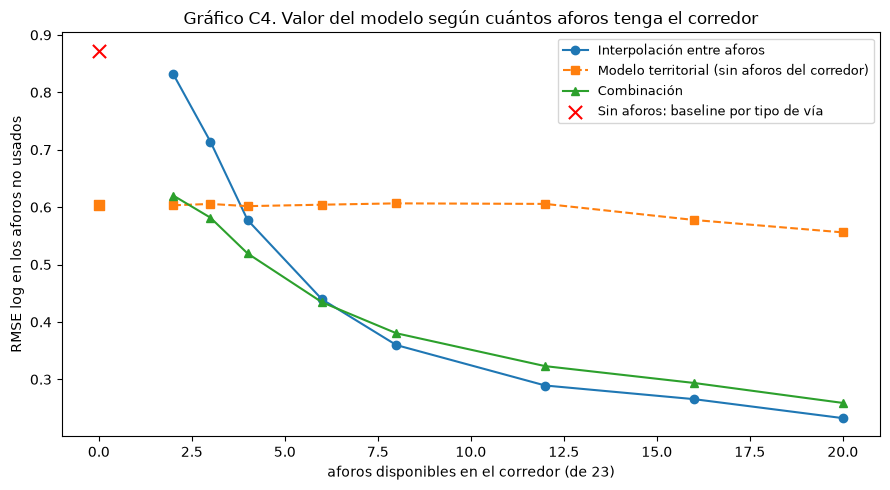

**Resultado.** Sin ningún aforo, el modelo tiene un RMSE log de 0.60 contra 0.87 del baseline (31% menos error). El modelo solo supera a la interpolación mientras el corredor tenga 3 aforos o menos (un aforo cada 116 km o más espaciados). La combinación es la mejor opción con entre 3 y 6 aforos. Con más aforos, interpolar es suficiente.

**Por lo tanto, el valor del modelo está en los corredores sin aforos o con aforos muy espaciados**, y en los huecos largos de un corredor que sí los tiene (como los km 180–220 de la MEX-095D). Donde hay aforos cercanos, el modelo sólo complementa.

In [8]:
# k = 0: baseline contra modelo
medias = y.groupby([train["road_tipo_vial"], train["fe_peaje"]]).mean()
p_base = medias.reindex(pd.MultiIndex.from_frame(T[["road_tipo_vial", "fe_peaje"]])).fillna(y.mean()).to_numpy()
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
SIN_AFOROS = {"baseline": rmse(yT, p_base), "modelo": rmse(yT, pT1)}

rng = np.random.default_rng(SEED)
L_KM, REPS, filas = 80.0, 300, []
for k in [2, 3, 4, 6, 8, 12, 16, 20]:
    err = {"interpolación": [], "modelo": [], "combinación": []}
    for _ in range(REPS):
        disp = np.sort(rng.choice(len(T), k, replace=False))
        fuera = np.setdiff1d(np.arange(len(T)), disp)
        interp = np.interp(km[fuera], km[disp], yT[disp])
        w = np.exp(-np.abs(km[fuera][:, None] - km[disp][None, :]).min(axis=1) / L_KM)
        err["interpolación"].append(rmse(yT[fuera], interp)); err["modelo"].append(rmse(yT[fuera], pT1[fuera]))
        err["combinación"].append(rmse(yT[fuera], w * interp + (1 - w) * pT1[fuera]))
    filas.append({"aforos_disponibles": k, "km_por_aforo": round((km.max() - km.min()) / k), **{a: np.mean(b) for a, b in err.items()}})
curva = pd.DataFrame(filas).set_index("aforos_disponibles")
curva.to_csv(OUT / "valor_sin_aforos.csv", encoding="utf-8-sig")
display(curva.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curva.index, curva["interpolación"], "o-", label="Interpolación entre aforos")
ax.plot(curva.index, curva["modelo"], "s--", label="Modelo territorial (sin aforos del corredor)")
ax.plot(curva.index, curva["combinación"], "^-", label="Combinación")
ax.scatter([0], [SIN_AFOROS["baseline"]], marker="x", s=90, color="red", zorder=5, label="Sin aforos: baseline por tipo de vía")
ax.scatter([0], [SIN_AFOROS["modelo"]], marker="s", s=60, color="tab:orange", zorder=5)
ax.set(xlabel="aforos disponibles en el corredor (de 23)", ylabel="RMSE log en los aforos no usados",
       title="Gráfico C4. Valor del modelo según cuántos aforos tenga el corredor")
ax.legend(fontsize=9); plt.tight_layout(); plt.savefig(OUT / "c4_valor_sin_aforos.png", dpi=120); plt.show()

gana_modelo = curva.index[curva["modelo"] < curva["interpolación"]]
gana_combo = curva.index[curva["combinación"] <= curva[["interpolación", "modelo"]].min(axis=1)]
k_m = int(gana_modelo.max()) if len(gana_modelo) else 0
k_c = f"entre {int(gana_combo.min())} y {int(gana_combo.max())}" if len(gana_combo) else "ningún número de"
display(Markdown(
    f"**Resultado.** Sin ningún aforo, el modelo tiene un RMSE log de {SIN_AFOROS['modelo']:.2f} contra {SIN_AFOROS['baseline']:.2f} del baseline "
    f"({100 * (1 - SIN_AFOROS['modelo'] / SIN_AFOROS['baseline']):.0f}% menos error). El modelo solo supera a la interpolación mientras el corredor "
    f"tenga {k_m} aforos o menos (un aforo cada {curva.loc[k_m, 'km_por_aforo'] if k_m else '—'} km o más espaciados). La combinación es la mejor "
    f"opción con {k_c} aforos. Con más aforos, interpolar es suficiente.\n\n"
    f"**Por lo tanto, el valor del modelo está en los corredores sin aforos o con aforos muy espaciados**, y en los huecos largos de un corredor "
    f"que sí los tiene (como los km 180–220 de la MEX-095D). Donde hay aforos cercanos, el modelo sólo complementa."))

## 4. Estimaciones corregidas para los CTN
Se aplican las mismas correcciones a la tabla de CTN: todos están sobre una autopista de cuota (`fe_peaje = 1`) y el flujo de paso se repara con los puntos del corredor (CTN y aforos) a 25 km o menos. El archivo del Avance 5 no se modifica; la versión corregida se guarda aparte.

In [9]:
ctn = pd.read_csv(TABLA_CTN, low_memory=False)
ctn_c = ctn.copy()
if usa_cuota:
    ctn_c["fe_peaje"] = 1
if usa_flujo:
    pts = pd.concat([ctn[["lat", "lon", "red_flujo_paso"]], T[["lat", "lon", "red_flujo_paso"]]], ignore_index=True)
    ctn_c["red_flujo_paso"] = reparar_flujo(pts, np.zeros(len(pts), dtype=int)).iloc[:len(ctn)].to_numpy()
salida = pd.DataFrame({"ctn_id": ctn["ctn_id"], "chainage_km": ctn["chainage_km"],
                       "tdpa_avance5": np.exp(modelo_a5.predict(ctn)).round(0),
                       "tdpa_corregido": np.exp(modelo_corr.predict(ctn_c)).round(0)})
salida["cambio_pct"] = (100 * (salida.tdpa_corregido / salida.tdpa_avance5 - 1)).round(1)
salida.to_csv(OUT / "predicciones_ctn_corregidas.csv", index=False, encoding="utf-8-sig")
print(f"CTN con fe_peaje = 0 en la tabla original: {(ctn.fe_peaje == 0).sum()} | con flujo de paso = 0: {(ctn.red_flujo_paso == 0).sum()} -> {(ctn_c.red_flujo_paso == 0).sum()}")
print(f"Cambio mediano: {salida.cambio_pct.median():+.1f}% | CTN que cambian más de 20%: {(salida.cambio_pct.abs() > 20).sum()}")
display(salida.reindex(salida.cambio_pct.abs().sort_values(ascending=False).index).head(8))

CTN con fe_peaje = 0 en la tabla original: 4 | con flujo de paso = 0: 5 -> 0
Cambio mediano: +22.8% | CTN que cambian más de 20%: 31


,ctn_id,chainage_km,tdpa_avance5,tdpa_corregido,cambio_pct
9,CTN_009,70.000,23326.0,39099.0,67.6
0,CTN_000,0.000,52694.0,83705.0,58.9
45,CTN_045,353.970,20865.0,32220.0,54.4
44,CTN_044,350.000,37321.0,56413.0,51.2
10,CTN_010,80.000,33433.0,49814.0,49.0
11,CTN_011,82.831,33545.0,48306.0,44.0
12,CTN_012,85.931,31210.0,44025.0,41.1
3,CTN_003,20.000,21190.0,29258.0,38.1


## 5. Conclusiones

**Sobre la subestimación en carreteras de alto tránsito**
- El modelo está calibrado respecto a lo que predice, pero no logra separar del todo a las autopistas troncales del resto. Ese aplanamiento es un límite de información, no de ajuste.
- Se encontraron dos defectos de datos en esas autopistas (cuota mal asignada y flujo de paso en cero). Al repararlos baja el error en todos los rangos de tránsito y el corredor MEX-095D se estima mejor (secciones 2 y 2.1).
- Ponderar los sitios de alto tránsito, por sí solo, mueve el error de un extremo al otro. La variante adoptada se eligió con una regla explícita (sección 2) y el sesgo que queda en el quintil alto se reporta tal cual.
- La corrección de fondo queda identificada: recalcular `red_flujo_paso` en `src/s09_red_features.py` considerando los dos cuerpos de la autopista y agregando los destinos del norte y el Bajío (hoy la lista de ciudades termina en Querétaro), y corregir la asignación de aforos a la RNC con el nombre de la carretera y el kilómetro.

**Sobre el valor del modelo**
- En un corredor **sin aforos**, el modelo es la mejor estimación disponible y supera con claridad al baseline.
- Con **pocos aforos**, conviene combinar: los aforos anclan el nivel y el modelo cubre los huecos.
- Con **muchos aforos** (como la MEX-095D), interpolar basta y el modelo sólo aporta en los tramos sin aforo cercano.

Las cifras exactas de cada punto están en los textos generados debajo de cada tabla, con los números de esta ejecución.

## 6. Contribución individual

| Integrante | Contribución en esta etapa | Contribución en el proyecto |
|---|---|---|
| Ana Karen [apellidos] | [completar] | [completar] |
| Quirec [apellidos] | [completar] | [completar] |
| Andrea Carolina Flores Ramírez | [completar] | [completar] |

## Declaración sobre el uso de herramientas de inteligencia artificial

Se utilizó Claude (Anthropic) como apoyo para diagnosticar la subestimación en carreteras de alto tránsito, proponer y programar las correcciones y el experimento de aforos disponibles, y redactar borradores de las interpretaciones. El equipo es responsable de revisar, ejecutar, interpretar y validar el código, los resultados y las conclusiones antes de la entrega.